<a href="https://colab.research.google.com/github/onurhayta/group59_CENG313/blob/main/assignment1_eda_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 1 — EDA and Baselines
**CENG313 Introduction to Data Science — GROUP59_CENG313**

Sadık Onur Hayta (23118080046)

Competition: [Hull Tactical – Market Prediction](https://www.kaggle.com/competitions/hull-tactical-market-prediction)

## 0. Setup

In [5]:
import os, sys

REPO_URL = "https://github.com/onurhayta/group59_CENG313.git"
REPO_DIR = "/content/group59_CENG313"

if "google.colab" in sys.modules:
    os.chdir("/content")
    if not os.path.exists(REPO_DIR):
        !git clone {REPO_URL} {REPO_DIR}
    else:
        !git -C {REPO_DIR} pull
    os.chdir(REPO_DIR)
sys.path.insert(0, os.getcwd())
print(os.getcwd(), os.listdir("src"))

remote: Enumerating objects: 4, done.
remote: Counting objects: 100% (4/4), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 3 (delta 1), reused 0 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (3/3), 3.64 KiB | 1.82 MiB/s, done.
From https://github.com/onurhayta/group59_CENG313
   1f37809..090b298  main       -> origin/main
Updating 1f37809..090b298
Fast-forward
 assignment1_eda_baseline.ipynb | 474 +++++++++++++++++++++++++++++++++++++++++
 1 file changed, 474 insertions(+)
 create mode 100644 assignment1_eda_baseline.ipynb
/content/group59_CENG313 ['models.py', 'data.py', '__init__.py', '__pycache__', 'utils.py']


In [6]:
!pip install -q -U "kagglehub>=0.4.1"

import kagglehub

if "google.colab" in sys.modules:
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

DATA_PATH = kagglehub.competition_download("hull-tactical-market-prediction")
print(DATA_PATH, os.listdir(DATA_PATH))

/root/.cache/kagglehub/competitions/hull-tactical-market-prediction ['test.csv', 'kaggle_evaluation', 'train.csv']


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data, models, utils

train = data.load_train(DATA_PATH)
print(train.shape)
train.head()

(9048, 98)


,date_id,D1,D2,D3,D4,D5,D6,D7,D8,D9,...,V3,V4,V5,V6,V7,V8,V9,forward_returns,risk_free_rate,market_forward_excess_returns
0,0,0,0,0,1,1,0,0,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.002421,0.000301,-0.003038
1,1,0,0,0,1,1,0,0,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.008495,0.000303,-0.009114
2,2,0,0,0,1,0,0,0,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.009624,0.000301,-0.010243
3,3,0,0,0,1,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.004662,0.000299,0.004046
4,4,0,0,0,1,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.011686,0.000299,-0.012301


## 1. Data overview

In [8]:
groups = data.group_features(train)
print("Rows:", len(train), "| date_id range:", train.date_id.min(), "-", train.date_id.max())

pd.DataFrame({
    "group": list(groups),
    "description": [data.FEATURE_GROUPS[g] for g in groups],
    "n_features": [len(cols) for cols in groups.values()],
})

Rows: 9048 | date_id range: 0 - 9047


,group,description,n_features
0,M,Market dynamics / technical,18
1,E,Macro-economic,20
2,I,Interest rates,9
3,P,Price / valuation,13
4,V,Volatility,13
5,S,Sentiment,12
6,D,Binary / dummy,9


The training set contains **9,048 trading days** (`date_id` 0–9047, roughly 36 years) and **94 anonymised features** in 7 groups. The `MOM*` group mentioned in some descriptions of the competition is not present in this version of the data. Dates are anonymised, so `date_id` only gives the order of the days.

In [9]:
train[data.TARGET_COLS].describe().T

,count,mean,std,min,25%,50%,75%,max
forward_returns,9048.0,0.000470,0.010535,-0.039754,-0.004321,0.000661,0.005891,0.040661
risk_free_rate,9048.0,0.000107,0.000088,-0.000004,0.000008,0.000099,0.000193,0.000317
market_forward_excess_returns,9048.0,0.000052,0.010552,-0.040582,-0.004751,0.000257,0.005469,0.040551


- `forward_returns` has a daily mean of 0.047% and a standard deviation of 1.05%, i.e. roughly 12% annual return and 17% annual volatility, which is realistic for the S&P 500.
- The minimum and maximum are almost symmetric at about ±4%. Real market crashes contain larger daily moves, so the target appears to be **clipped (winsorised)**.
- `market_forward_excess_returns` has a mean close to zero (0.005%), much smaller than `forward_returns − risk_free_rate` (≈0.036%). It is therefore not a simple excess return over the risk-free rate; it appears to be demeaned with a rolling long-term average. This is the target our models predict.
- The daily signal is tiny compared with the noise (mean ≈ 0.05 × std), which already suggests that predicting daily returns will be hard.

## 2. Exploratory data analysis
### 2.1 Missing values

In [10]:
miss = data.missing_summary(train)
miss.groupby("group").agg(
    n_features=("feature", "count"),
    mean_missing_ratio=("missing_ratio", "mean"),
    first_available=("first_valid_date_id", "min"),
    last_to_start=("first_valid_date_id", "max"),
).sort_values("mean_missing_ratio")

,n_features,mean_missing_ratio,first_available,last_to_start
group,,,,
D,9,0.000000,0,0
I,9,0.111185,1006,1006
P,13,0.126573,1006,1638
E,20,0.151807,1006,6969
V,13,0.196984,1006,6049
S,12,0.201131,1006,5733
M,18,0.253303,1006,5547


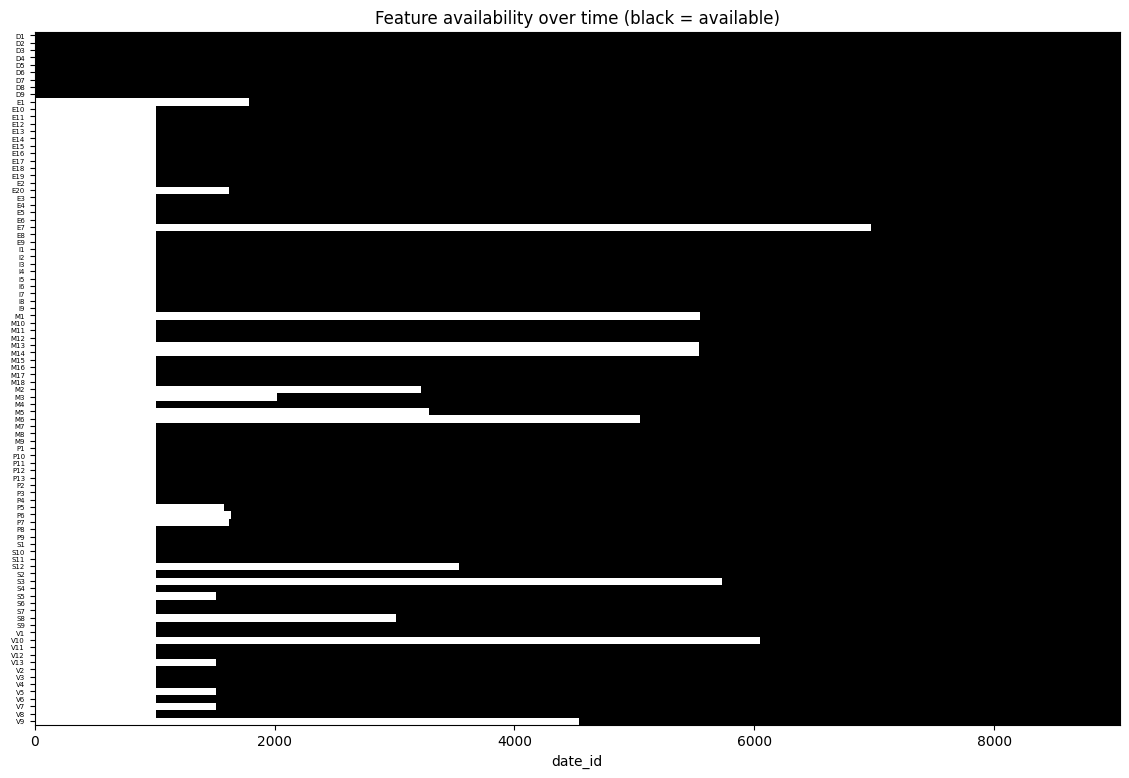

In [11]:
feats = data.get_feature_columns(train)

fig, ax = plt.subplots(figsize=(14, 9))
ax.imshow(train[feats].notna().T, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_yticks(range(len(feats)))
ax.set_yticklabels(feats, fontsize=5)
ax.set_xlabel("date_id")
ax.set_title("Feature availability over time (black = available)")
plt.show()

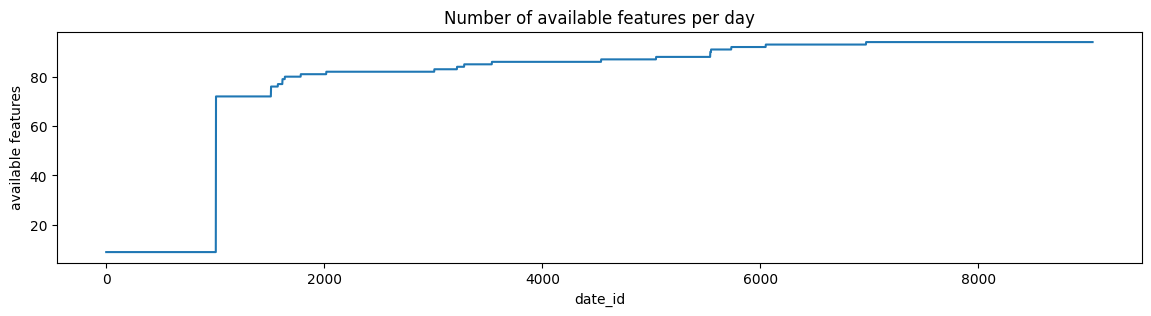

In [12]:
fig, ax = plt.subplots(figsize=(14, 3))
train[feats].notna().sum(axis=1).plot(ax=ax)
ax.set_xlabel("date_id")
ax.set_ylabel("available features")
ax.set_title("Number of available features per day")
plt.show()

**Findings:**
- For the **first 1,006 days only the 9 binary `D*` features are available**; all other groups are completely missing.
- At `date_id` 1006 about 72 features become available at once, and the number then grows step by step to all 94.
- Some features start very late: e.g. `E7` (~day 6969), `V10` (~6049), `S3` (~5733), `M1`/`M13` (~5547), so they exist only for the most recent part of the data.
- Missingness is structural (features start at a given date and stay available), not random gaps.

**Implications for modelling:**
- The first 1,006 rows carry almost no information and will be excluded from training.
- Linear models need imputation (median imputation in our Ridge baseline). LightGBM can handle missing values natively.
- Features that start late have little training history, so their relationships with the target are estimated from fewer observations.